In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import os 
from pathlib import Path

import zarr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import matplotlib.colors as mcolors
from matplotlib import gridspec
import seaborn as sns
from dotenv import dotenv_values

from hm3d_utils.plotting import plot_clusters_collapsed, plot_single_cluster


In [3]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Ext_Fig_06"
os.makedirs(OUTDIR, exist_ok=True)

ST_FP = DATADIR / "9_objects" / "spatial" / 'hypomap3d_spatial_voxel_level.zarr'

In [4]:
store = zarr.open(ST_FP, mode='r')

### Plot all target L3 clusters

In [5]:
target_clusters = ['Gb3-228', "Gl3-103", "Gl3-118", "Gb3-145", "Gl3-18", ]

Gb3-228


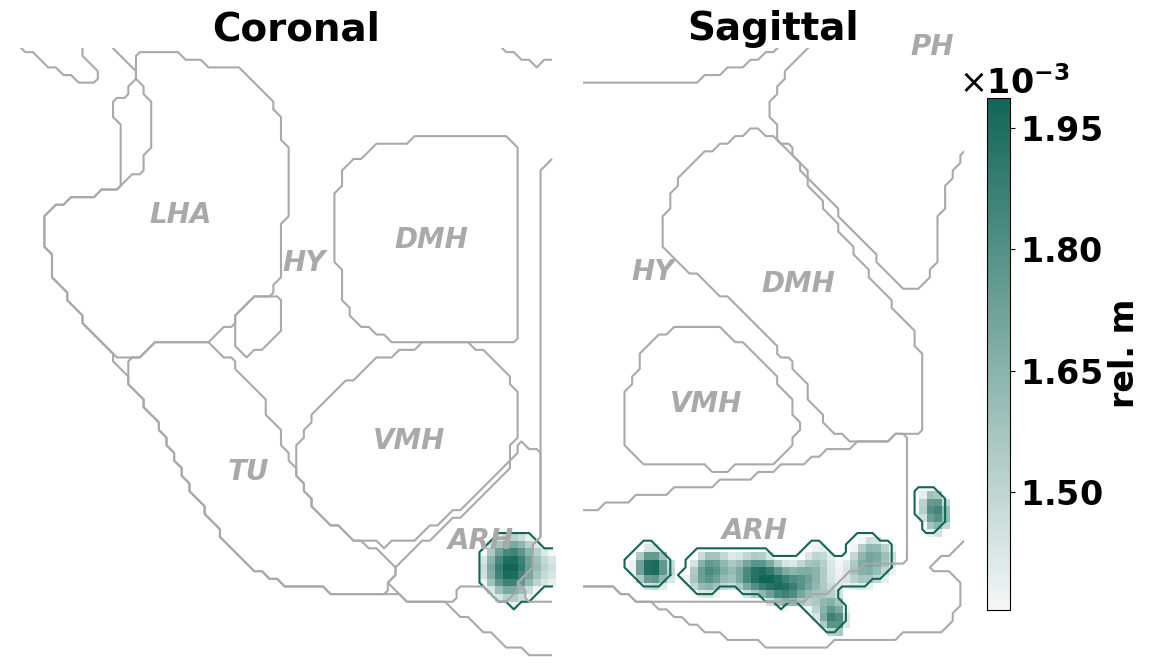

Gl3-103


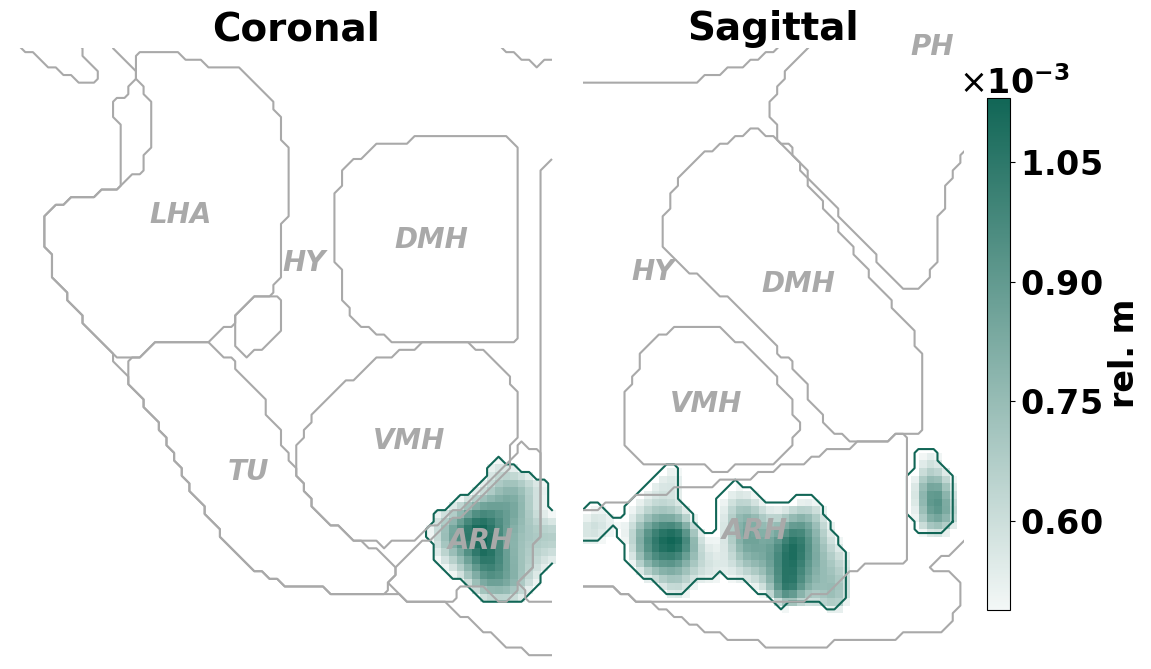

Gl3-118


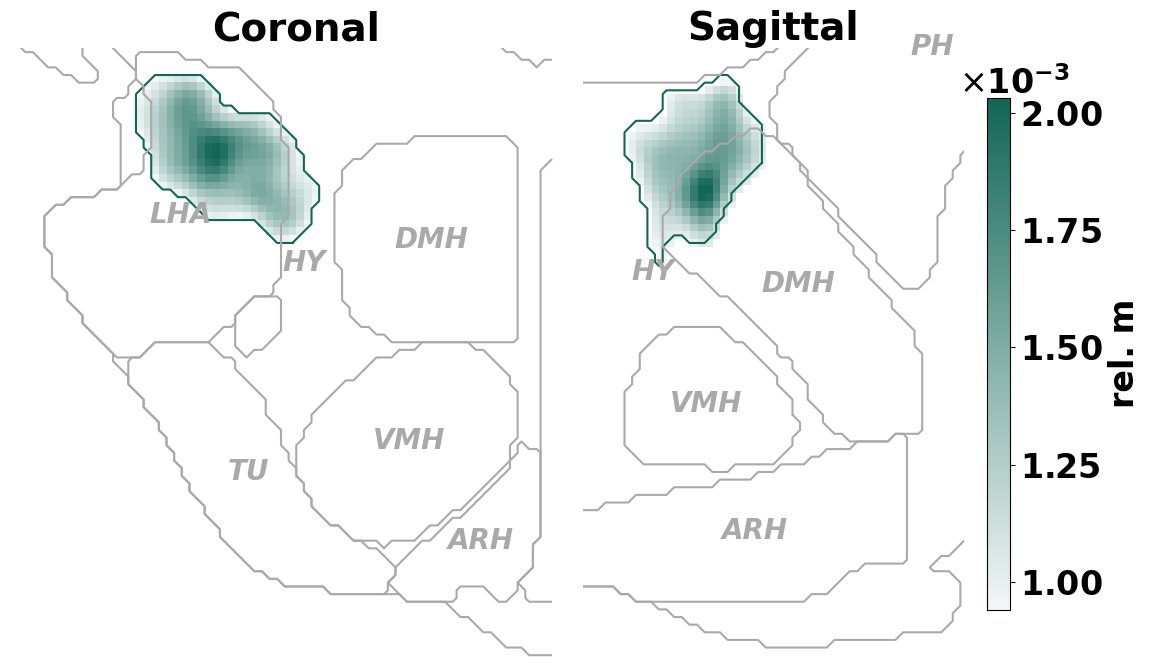

Gb3-145


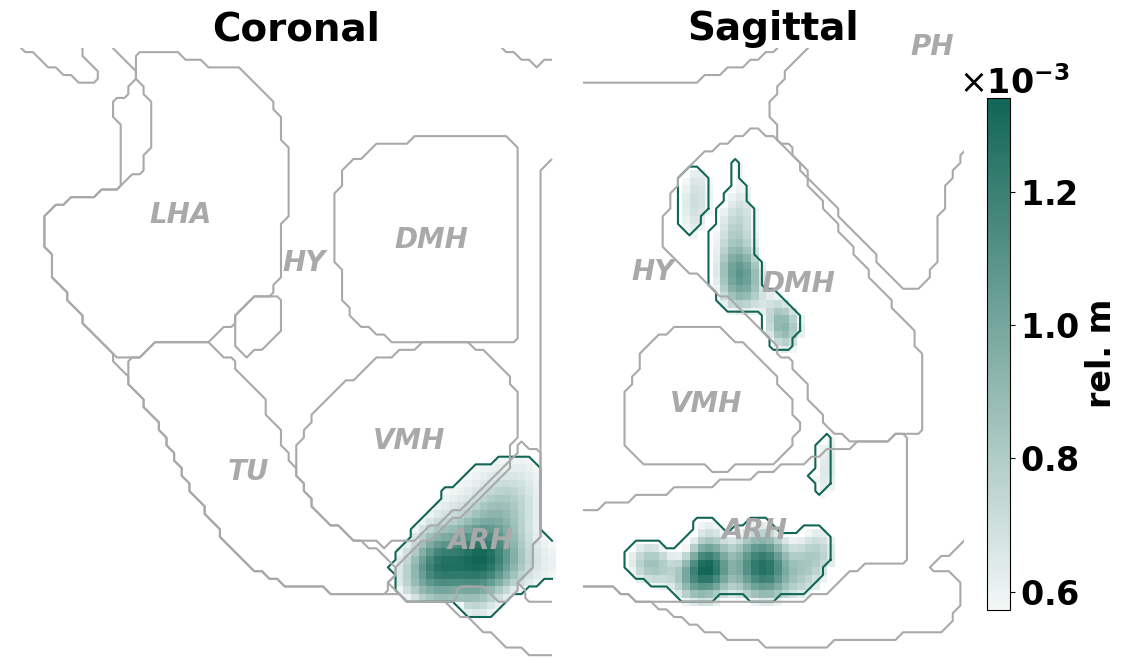

Gl3-18


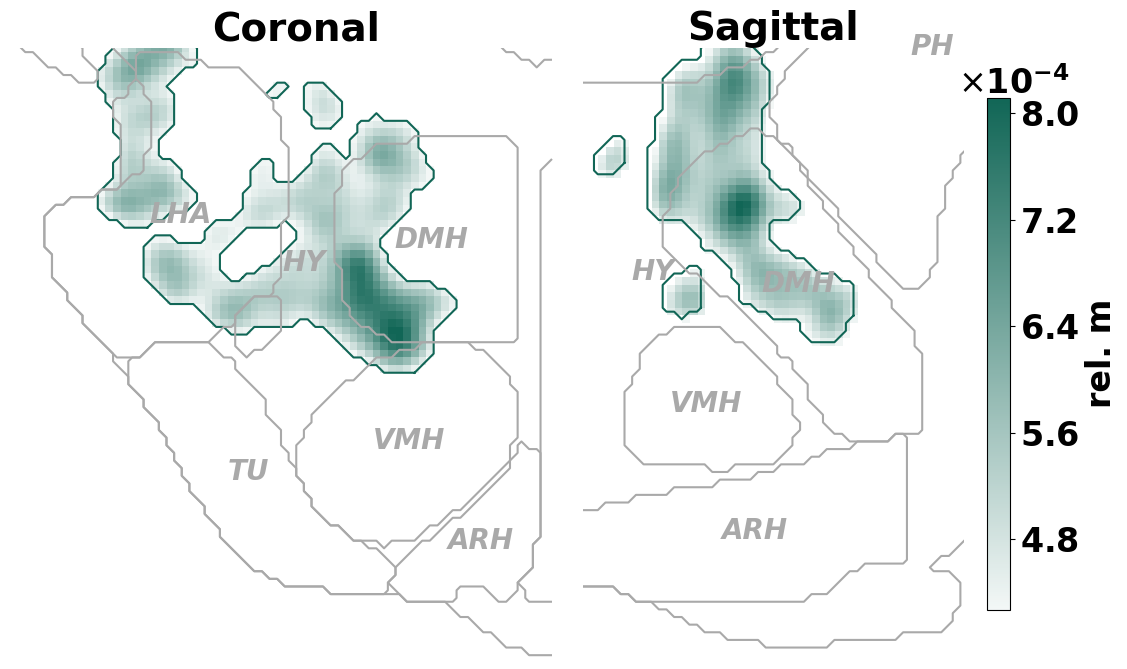

In [13]:
# All clusters in a loop
for cluster in target_clusters:
    print(cluster)
    color_to_use = "#116656"

    # ── Shared parameters ────────────────────────────────────────────────────────
    shared_params = dict(
        store          = store,
        cluster_id=cluster,
        slice_range    = (80, 130),
        mass_threshold      = 0.4,   
        axis0_range    = (60, 140),
        figsize        = (10, 10),
        label_fontsize = 28,
        region_label_fontsize = 20,
        outline_linewidth = 1.5,      
        region_linewidth  = 1.5,
        fill_mode      = 'density',  
        cluster_color  = color_to_use,
        make_colorbar_bold=True,
        colorbar_n_ticks = 5,
        colorbar_tick_fontsize=24,
        colorbar_label_fontsize=24,
        title_bold=True,
        region_labels_bold=True

    )

    # ── Per-view parameters ───────────────────────────────────────────────────────
    coronal_params = dict(
        regions     = ['HY', 'ARH', 'DMH', 'VMH', 'LHA','TU'],
        view        = 'coronal',
        axis1_range = (35, 110),
        title = f"Coronal"
    )

    sagittal_params = dict(
        regions     = ['HY', 'ARH', 'DMH', 'VMH', 'AHN', 'PH', "TU"],
        view        = 'sagittal',
        axis1_range = (80, 130),
        title = f"Sagittal",
        add_colorbar=True,
    )

    # ── Figure layout based on actual data ranges ─────────────────────────────────
    dv_range   = shared_params['axis0_range']
    coronal_w  = coronal_params['axis1_range'][1]  - coronal_params['axis1_range'][0]
    sagittal_w = sagittal_params['axis1_range'][1] - sagittal_params['axis1_range'][0]
    height     = dv_range[1] - dv_range[0]
    scale      = 0.08

    fig = plt.figure(figsize=((coronal_w + sagittal_w) * scale, height * scale))
    gs  = gridspec.GridSpec(1, 4,
                            width_ratios = [coronal_w, sagittal_w, 3, 3],
                            wspace       = 0,
                            left=0, right=1, top=1, bottom=0)


    axes = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1]), fig.add_subplot(gs[-1]),]

    pos = axes[2].get_position()

    axes[2].set_position([
        pos.x0,
        pos.y0 + 0.1 * pos.height,
        pos.width,
        0.8 * pos.height,
    ])

    # ── Plot - merge dicts so per-view params override shared ones ────────────────
    plot_single_cluster(**{**shared_params, **coronal_params},  ax=axes[0])
    plot_single_cluster(**{**shared_params, **sagittal_params}, ax=axes[1], cbar_ax=axes[-1], )

    # Define output path and filename
    filename = OUTDIR / f'cluster_contour_{cluster}.pdf'
    # Set figure size (width, height) in inches
   # fig.set_size_inches(12, 6)
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()